In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('default')
import fspiderman as sp
from astro_utils import *
from HItargets_utils import hi_planets_by_name

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
t0=0.

# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = K2_141b.args

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

## Zhang and Showman 2017

In [3]:
spider_params = sp.ModelParams(brightness_model="zhang", stellar_model="blackbody") # stellar model can also be custom or PHOENIX
spider_params.n_layers= 20

In [4]:
spider_params.t0= t0                # Central time of PRIMARY transit [days]
spider_params.per= period           # Period [days]
spider_params.a_abs= a_AU           # The absolute value of the semi-major axis [AU]
spider_params.inc= incl             # Inclination [degrees]
spider_params.ecc= ecc              # Eccentricity
spider_params.w= w                  # Argument of periastron
spider_params.rp= rp                # Planet to star radius ratio
spider_params.a= a                  # Semi-major axis scaled by stellar radius    
spider_params.p_u1=spider_params.p_u2= 0.  # PLANETARY limb darkening parameters (default=0, relevant for thick planetary atmospheres, molten or regolith surface could in principle introduce weak non-Lambertian/limb-darkening behavior)

In [5]:
# Parameters specific to Zhang and Showman 2017 model

spider_params.xi= 0.                # Ratio of radiative to advective timescale
spider_params.T_n= 300             # Temperature of nightside [K]
spider_params.delta_T= 3000          # Day-night temperature contrast [K]
spider_params.T_s = T_eff            # Temperature of the star [K]

In [6]:
spider_params.l1 = 1.1e-6       # The starting wavelength in meters
spider_params.l2 = 1.7e-6       # The ending wavelength in meters

In [7]:
min_temp = spider_params.T_n-50
max_temp = spider_params.T_n + spider_params.delta_T

In [8]:
t= spider_params.t0 + np.linspace(0, spider_params.per,100)

#### Brightness Maps

/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/fspiderman/plot.py:133: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 924.855x800 with 5 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(mycax, cax=cbar_ax)


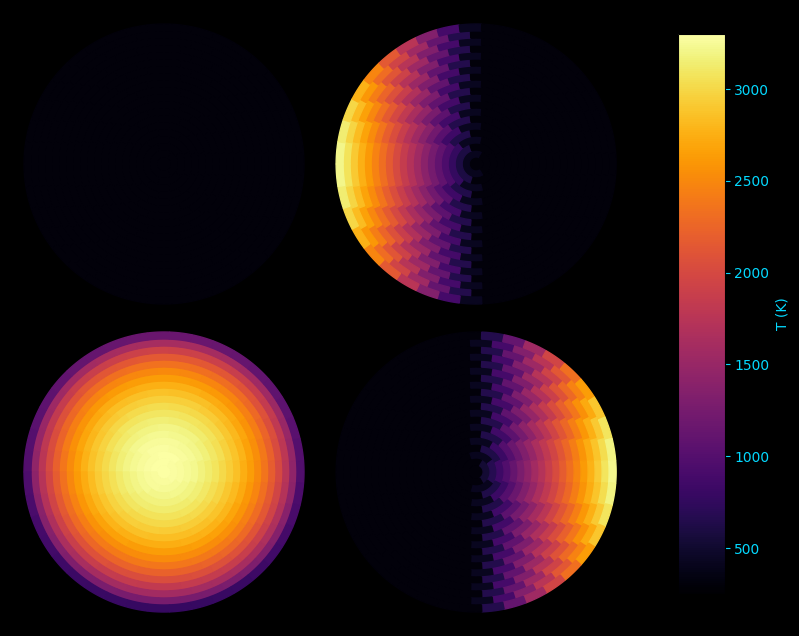

/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/fspiderman/plot.py:642: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 640x480 with 2 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(mycax, cax=cax)


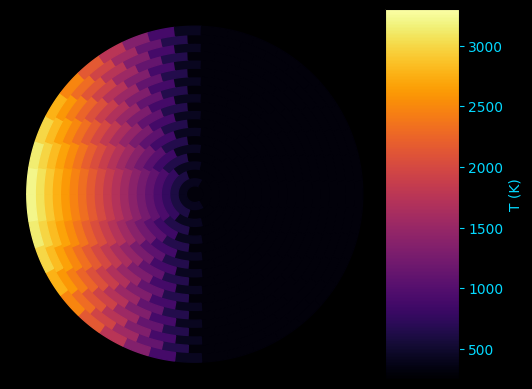

In [9]:
spider_params.plot_quad(min_temp=min_temp,max_temp=max_temp,temp_map=True,theme='black')
plt.show()

phase = 0.25
spider_params.plot_planet(phase,use_phase=True,min_temp=min_temp,max_temp=max_temp,temp_map=True, theme='black')
plt.show()

#### Phase Curve

no stellar models provided, using blackbody approximation


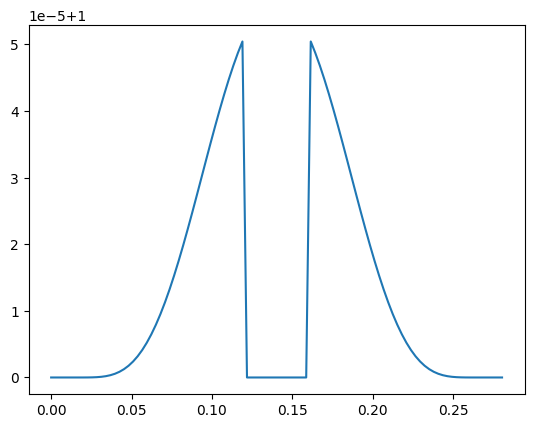

no stellar models provided, using blackbody approximation
Occultation depth: 56.7 ppm


In [10]:
lc = spider_params.lightcurve(t)
plt.plot(t,lc)
plt.show()

print(f"Occultation depth: {spider_params.eclipse_depth()*1e6:.1f} ppm")

## Two sided planet (Two temperature model)

In [11]:
spider_params = sp.ModelParams(brightness_model="two temperature", stellar_model="blackbody") # stellar model can also be custom or PHOENIX
spider_params.n_layers= 20

In [12]:
spider_params.t0= t0                # Central time of PRIMARY transit [days]
spider_params.per= period           # Period [days]
spider_params.a_abs= a_AU           # The absolute value of the semi-major axis [AU]
spider_params.inc= incl             # Inclination [degrees]
spider_params.ecc= ecc              # Eccentricity
spider_params.w= w                  # Argument of periastron
spider_params.rp= rp                # Planet to star radius ratio
spider_params.a= a                  # Semi-major axis scaled by stellar radius
spider_params.p_u1=spider_params.p_u2= 0.  # PLANETARY limb darkening parameters (default=0, relevant for thick planetary atmospheres, molten or regolith surface could in principle introduce weak non-Lambertian/limb-darkening behavior)

In [13]:
# Parameters specific to Two Temperatures Model

spider_params.T_p_d= 3000           # Temperature of dayside [K]
spider_params.T_p_n= 1128           # Temperature of nightside [K]
spider_params.T_s = T_eff            # Temperature of the star [K]

In [14]:
spider_params.l1 = 1.1e-6       # The starting wavelength in meters
spider_params.l2 = 1.7e-6       # The ending wavelength in meters

In [15]:
min_temp = spider_params.T_p_n-50
max_temp = spider_params.T_p_d

In [16]:
t= spider_params.t0 + np.linspace(0, spider_params.per,100)

#### Brightness Maps

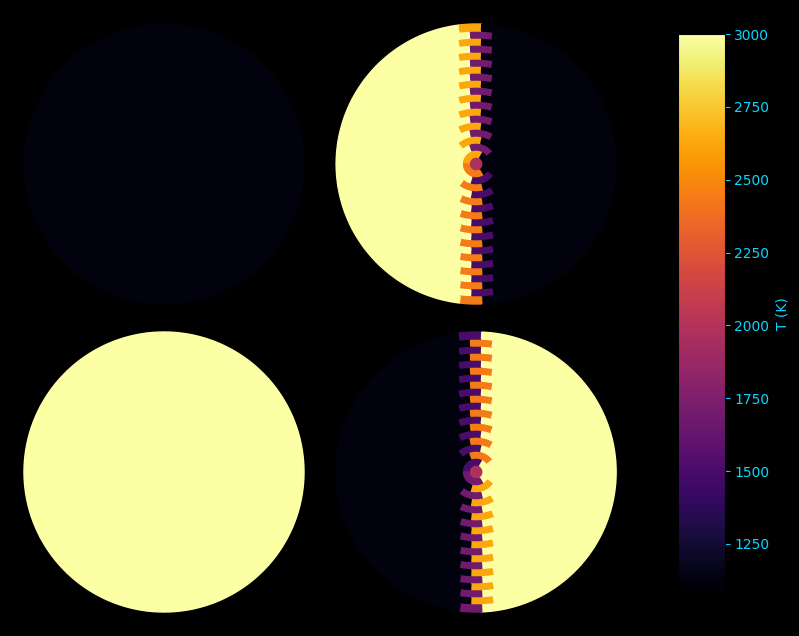

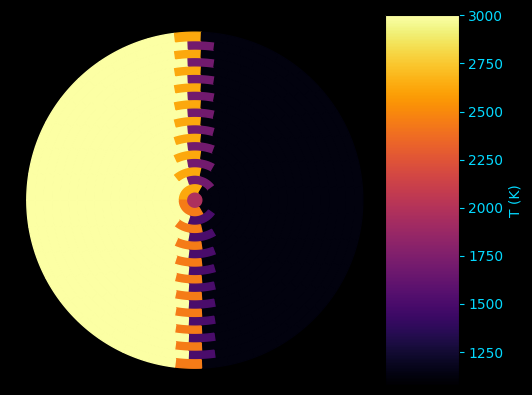

In [17]:
spider_params.plot_quad(min_temp=min_temp,max_temp=max_temp,temp_map=True,theme='black')
plt.show()

phase = 0.25
spider_params.plot_planet(phase,use_phase=True,min_temp=min_temp,max_temp=max_temp,temp_map=True, theme='black')
plt.show()

#### Phase Curve

no stellar models provided, using blackbody approximation


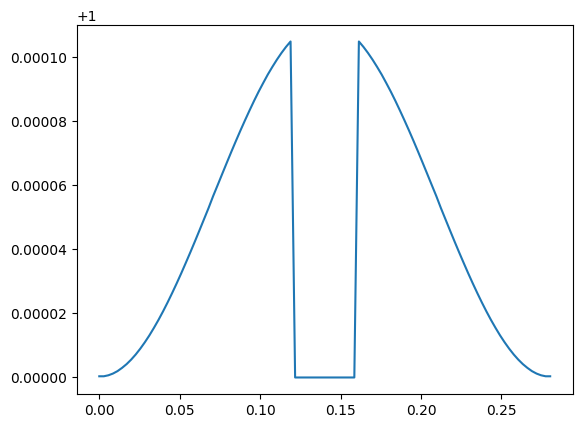

In [18]:
lc = spider_params.lightcurve(t)
plt.plot(t,lc)

## Lambertian reflection

In [19]:
spider_params = sp.ModelParams(brightness_model="lambertian", stellar_model="blackbody") # stellar model can also be custom or PHOENIX
spider_params.n_layers= 20

In [20]:
spider_params.t0= t0                # Central time of PRIMARY transit [days]
spider_params.per= period           # Period [days]
spider_params.a_abs= a_AU           # The absolute value of the semi-major axis [AU]
spider_params.inc= incl             # Inclination [degrees]
spider_params.ecc= ecc              # Eccentricity
spider_params.w= w                  # Argument of periastron
spider_params.rp= rp                # Planet to star radius ratio
spider_params.a= a                  # Semi-major axis scaled by stellar radius
spider_params.p_u1=spider_params.p_u2= 0.  # PLANETARY limb darkening parameters (default=0, relevant for thick planetary atmospheres, molten or regolith surface could in principle introduce weak non-Lambertian/limb-darkening behavior)

In [21]:
# Parameters specific to Lambertian reflection model

spider_params.albedo = 0.3          # Geometric/Lambertian albedo of the planet
spider_params.T_s = T_eff            # Temperature of the star [K] (needed to compute the reflected flux in the given band)

# spiderman quirk: ModelParams sets thermal=False for "lambertian", but plot_planet/plot_quad only build the stellar grid needed to render a brightness map when thermal==True (regardless of brightness_model) -- without this the plotting calls below crash in the C backend. The lightcurve() computation itself is unaffected and works fine either way.
spider_params.thermal = True

In [22]:
spider_params.l1 = 1.1e-6       # The starting wavelength in meters
spider_params.l2 = 1.7e-6       # The ending wavelength in meters

In [23]:
t= spider_params.t0 + np.linspace(0, spider_params.per,100)

#### Brightness Maps

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


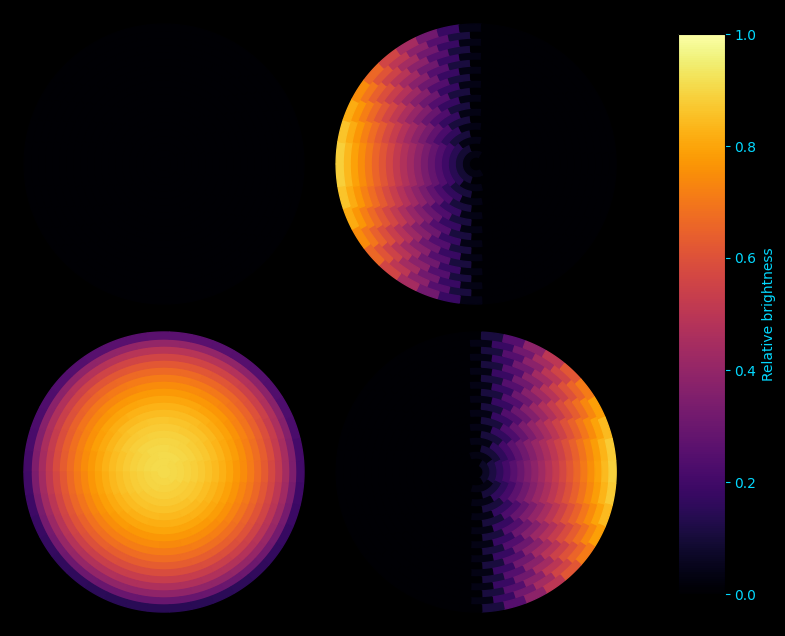

no stellar models provided, using blackbody approximation


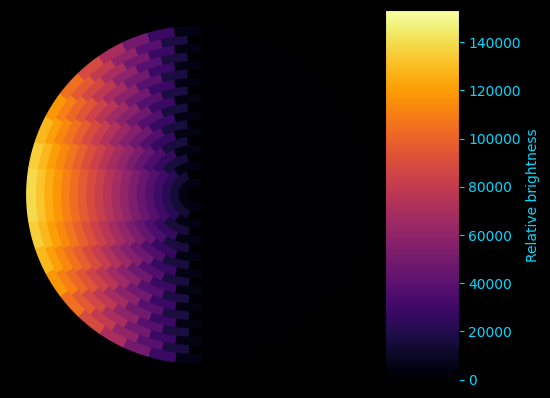

In [24]:
spider_params.plot_quad(temp_map=False,theme='black')
plt.show()

phase = 0.25
spider_params.plot_planet(phase,use_phase=True,temp_map=False, theme='black')
plt.show()

#### Phase Curve

no stellar models provided, using blackbody approximation


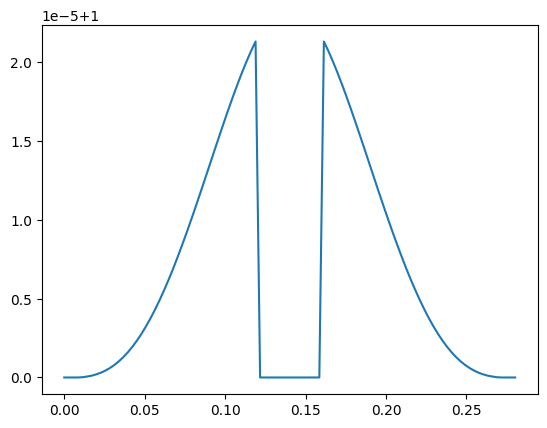

In [25]:
lc = spider_params.lightcurve(t)
plt.plot(t,lc)

## Combine (Zhang thermal emission + Lambertian reflection)

In [26]:
spider_params = sp.ModelParams(brightness_model="combine", stellar_model="blackbody") # stellar model can also be custom or PHOENIX
spider_params.n_layers= 20

In [27]:
spider_params.t0= t0                # Central time of PRIMARY transit [days]
spider_params.per= period           # Period [days]
spider_params.a_abs= a_AU           # The absolute value of the semi-major axis [AU]
spider_params.inc= incl             # Inclination [degrees]
spider_params.ecc= ecc              # Eccentricity
spider_params.w= w                  # Argument of periastron
spider_params.rp= rp                # Planet to star radius ratio
spider_params.a= a                  # Semi-major axis scaled by stellar radius
spider_params.p_u1=spider_params.p_u2= 0.  # PLANETARY limb darkening parameters (default=0, relevant for thick planetary atmospheres, molten or regolith surface could in principle introduce weak non-Lambertian/limb-darkening behavior)

In [28]:
# Parameters specific to Combine (Zhang + Lambertian) model

spider_params.xi= 0.                # Ratio of radiative to advective timescale
spider_params.T_n= 1128             # Temperature of nightside [K]
spider_params.delta_T= 942          # Day-night temperature contrast [K]
spider_params.T_s = T_eff            # Temperature of the star [K]
spider_params.albedo = 0.3          # Geometric/Lambertian albedo of the reflected component

In [29]:
spider_params.l1 = 1.1e-6       # The starting wavelength in meters
spider_params.l2 = 1.7e-6       # The ending wavelength in meters

In [30]:
min_temp = spider_params.T_n-50
max_temp = spider_params.T_n + spider_params.delta_T

In [31]:
t= spider_params.t0 + np.linspace(0, spider_params.per,100)

#### Brightness Maps

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


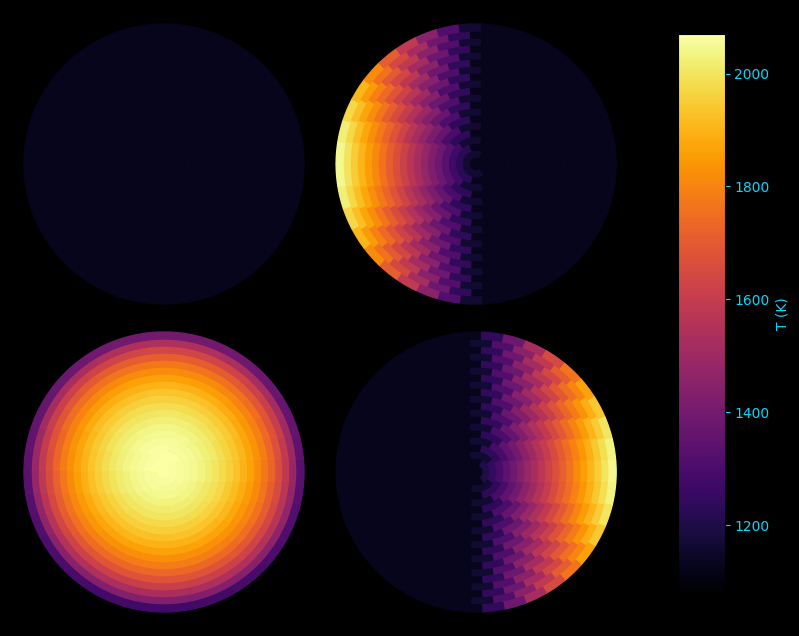

no stellar models provided, using blackbody approximation


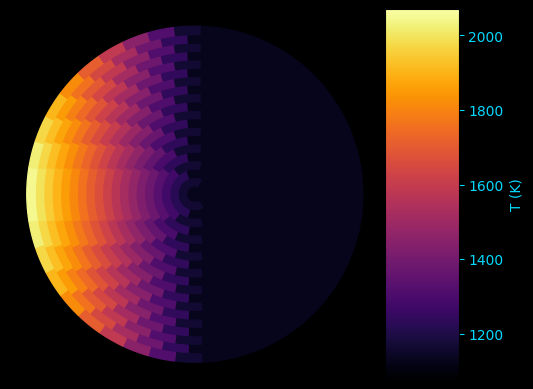

In [32]:
spider_params.plot_quad(min_temp=min_temp,max_temp=max_temp,temp_map=True,theme='black')
plt.show()

phase = 0.25
spider_params.plot_planet(phase,use_phase=True,min_temp=min_temp,max_temp=max_temp,temp_map=True, theme='black')
plt.show()

#### Phase Curve

no stellar models provided, using blackbody approximation


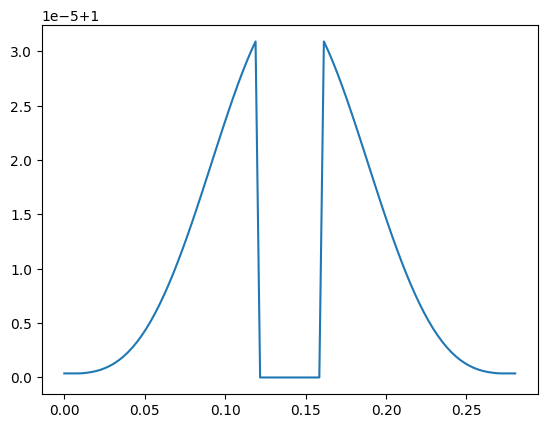

In [33]:
lc = spider_params.lightcurve(t)
plt.plot(t,lc)